In [1]:
#Beginning pseudospectral coding stuff
import numpy as np
import matplotlib.pyplot as plt

#TRANSFORMATION PROCESS:
    #Physical Space: u and q --> Values at each position along the pipe
    #Fourier Space: uh and qh --> Fourier coefficients representing the spatial patterns
    #Physical Space: u and q --> Can then put into physical equations

#Parameters for model
zeta = 0.8
eta = 0 #unsure how to implement, not necessary if sigma is 0
D = 0.5
delta = 0.1
e_1 = 0.1
e_2 = 0.2
sigma = 0
U_dash, U_0 = 1, 2 
r_value = 0.9
save_every = 50

if sigma!=0:
    print("sigma not equal to 0, check eta value.")

#Parameters for pseudospectral methods
L, N = 2*np.pi, 128
x = np.linspace(0, L, N, endpoint=False)    #ensures that we don't count the same point twice given the periodic boundary conditions
dt, T = 0.0001, 5
k = 2*np.pi * np.fft.fftfreq(N, d=L/N)      #gives wavenumbers
ik = 1j*k                                   #writing out ik in python terms --> this is an array of imaginary numbers
ik[N//2] = 0                                #making the derivative real and uniquely defined as odd-derivatives are anti-symmetric here
                                            # we are zeroing the nyquist mode (setting to 0)
dealias = np.abs(k) < (2/3) * np.abs(k).max()  #2/3 rule
nsteps = int(round(T/dt))

#Initialisation
u0 = np.ones(N)
q0 = 1 + 0.5*np.exp(-10*(x - np.pi)**2)
uh, qh = np.fft.fft(u0)*dealias, np.fft.fft(q0)*dealias #transforming into fourier space + dealiasing (remove the false errors)

def rhs(uh, qh, r):
    #(1): Back to grid space for the non-linear terms
    u, q = np.fft.ifft(uh).real, np.fft.ifft(qh).real
    ux, qx, = np.fft.ifft(ik * uh).real, np.fft.ifft(ik * qh).real #spectrally computed derivatives 
    qxx = np.fft.ifft(-k**2 * qh).real

    #(2): Defining f and g and Method Of Lines terms 
    f = q*(r + u - U_0 - (r + delta)*(q - 1)**2)
    g = e_1*(U_0 - u) + e_2*(U_dash - u)*q

    du_rhs = g - u*ux
    dq_rhs = f + D*qxx + sigma*q*eta - (u - zeta)*qx

    duh = np.fft.fft(du_rhs) * dealias
    dqh = np.fft.fft(dq_rhs) * dealias

    return duh, dqh

def rk4_step(uh, qh, dt, r):
    k1u, k1q = rhs(uh, qh, r)
    k2u, k2q = rhs(uh + 0.5*dt*k1u, qh + 0.5*dt*k1q, r)
    k3u, k3q = rhs(uh + 0.5*dt*k2u, qh + 0.5*dt*k2q, r)
    k4u, k4q = rhs(uh + dt*k3u, qh + dt*k3q, r)
    uh = uh + dt/6*(k1u + 2*k2u + 2*k3u + k4u)
    qh = qh + dt/6*(k1q + 2*k2q + 2*k3q + k4q)

    return uh, qh

u_series = []
q_series = []
t_series = []

uh1 = uh.copy()
qh1 = qh.copy()

for n in range(nsteps):
    uh, qh = rk4_step(uh, qh, dt, r_value)
    u, q = np.fft.ifft(uh).real, np.fft.ifft(qh).real
    
    if (n+1) % save_every == 0:
        u_series.append(u.copy())
        q_series.append(q.copy())
        t_series.append((n+1)*dt)

if np.array_equal(uh1, uh) or np.array_equal(qh1, qh):
    print("ERROR")

u_series = np.stack(u_series)
q_series = np.stack(q_series)
t_series = np.array(t_series)


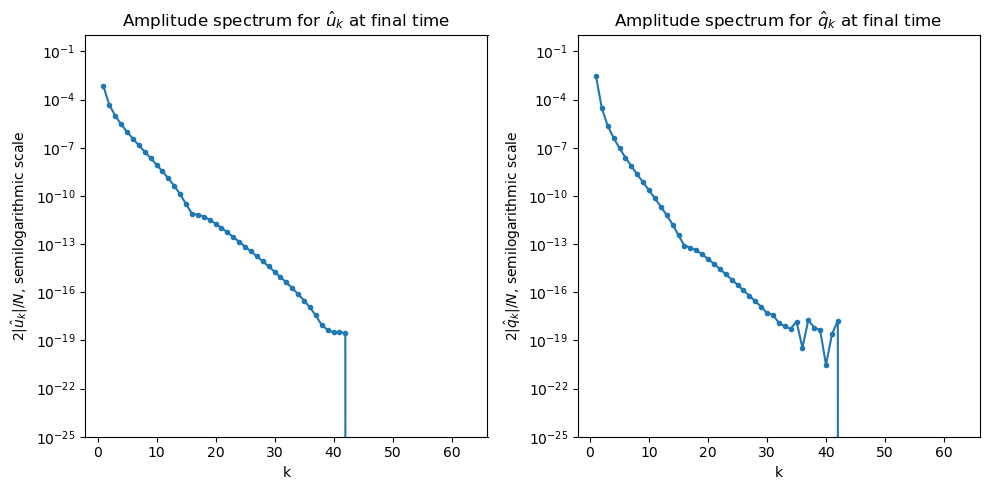

In [2]:
half = slice(1, N//2) #positive wavenumbers only (don't need duplicates)

fig, ax = plt.subplots(1, 2, figsize = (10,5))
ax[0].semilogy(k[half], 2*np.abs(uh[half]/N), marker='o', ms=3)
ax[0].set_xlabel("k")
ax[0].set_ylabel(r"$2|\hat u_k|/N$, semilogarithmic scale")
ax[0].set_title(r"Amplitude spectrum for $\hat u_k$ at final time ")
ax[0].set_ylim(1e-25, 1)

ax[1].semilogy(k[half], 2*np.abs(qh[half]/N), marker='o', ms=3)
ax[1].set_xlabel("k")
ax[1].set_ylabel(r"$2|\hat q_k|/N$, semilogarithmic scale")
ax[1].set_title(r"Amplitude spectrum for $\hat q_k$ at final time ")
ax[1].set_ylim(1e-25, 1)

plt.tight_layout()
plt.show()

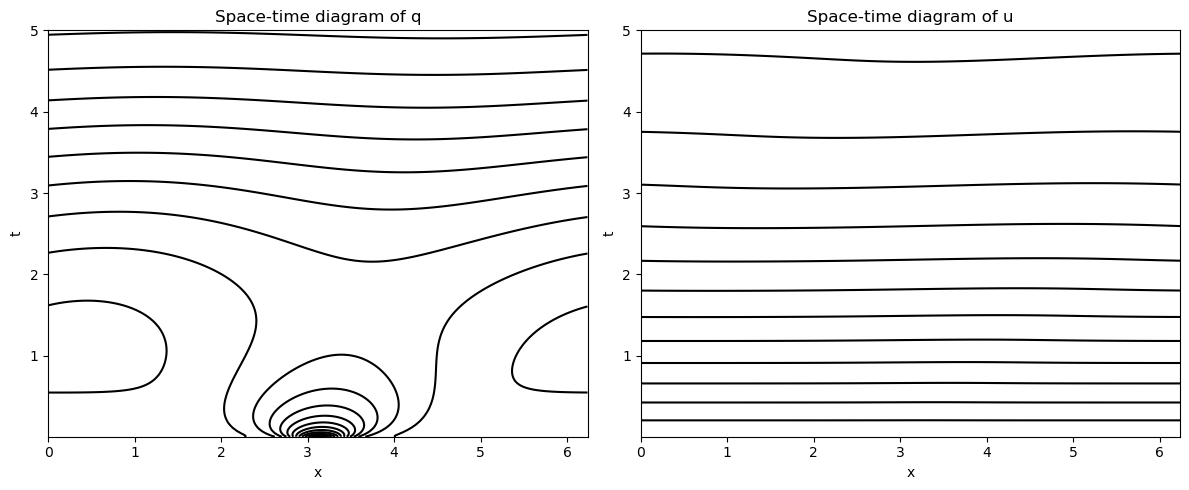

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].contour(x, t_series, q_series, levels=15,colors='black')
ax[0].set_xlabel('x')
ax[0].set_ylabel('t')
ax[0].set_title('Space-time diagram of q')

ax[1].contour(x, t_series, u_series, levels=15, colors='black')

ax[1].set_xlabel('x')
ax[1].set_ylabel('t')
ax[1].set_title('Space-time diagram of u')

plt.tight_layout()
plt.show()

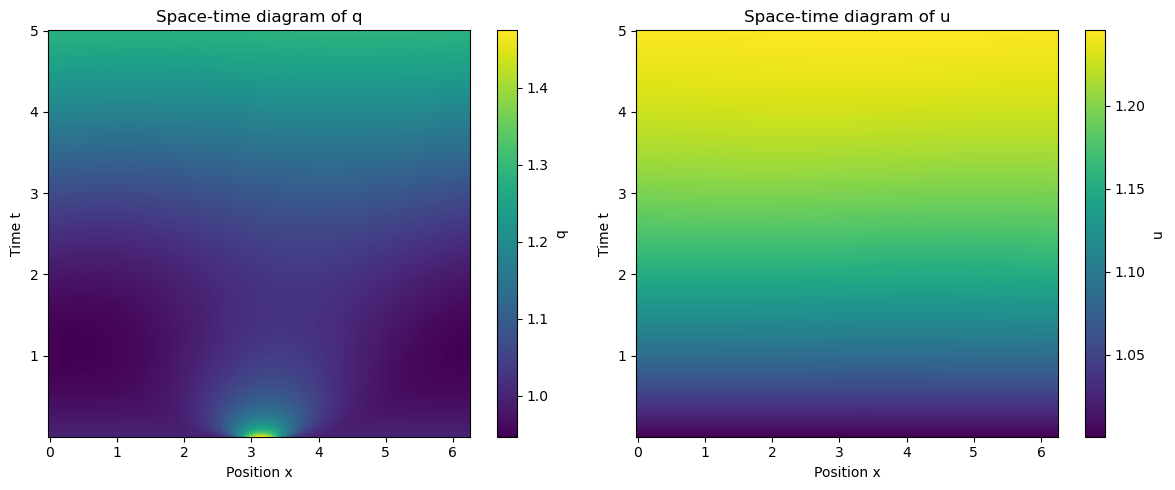

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Space-time diagram of q
mesh1 = ax[0].pcolormesh(
    x, t_series, q_series,
    shading='auto',
    cmap='viridis'
)

ax[0].set_xlabel('Position x')
ax[0].set_ylabel('Time t')
ax[0].set_title('Space-time diagram of q')

fig.colorbar(mesh1, ax=ax[0], label='q')

# Space-time diagram of u
mesh2 = ax[1].pcolormesh(
    x, t_series, u_series,
    shading='auto',
    cmap='viridis'
)

ax[1].set_xlabel('Position x')
ax[1].set_ylabel('Time t')
ax[1].set_title('Space-time diagram of u')

fig.colorbar(mesh2, ax=ax[1], label='u')

plt.tight_layout()
plt.show()

In [5]:
#started running for multiple r 
def run_simulation(r):

    # Start from the same initial conditions each time
    uh = np.fft.fft(u0) * dealias
    qh = np.fft.fft(q0) * dealias

    u_series = []
    q_series = []
    t_series = []

    for n in range(nsteps):
        uh, qh = rk4_step(uh, qh, dt, r)

        if (n+1) % save_every == 0:
            u = np.fft.ifft(uh).real
            q = np.fft.ifft(qh).real

            u_series.append(u.copy())
            q_series.append(q.copy())
            t_series.append((n+1)*dt)

    return (np.stack(u_series), np.stack(q_series),np.array(t_series))

r_values = [0.3, 0.6, 0.9]
results = {}

for i in r_values:
    results[i] = run_simulation(i) #run simulation for each r


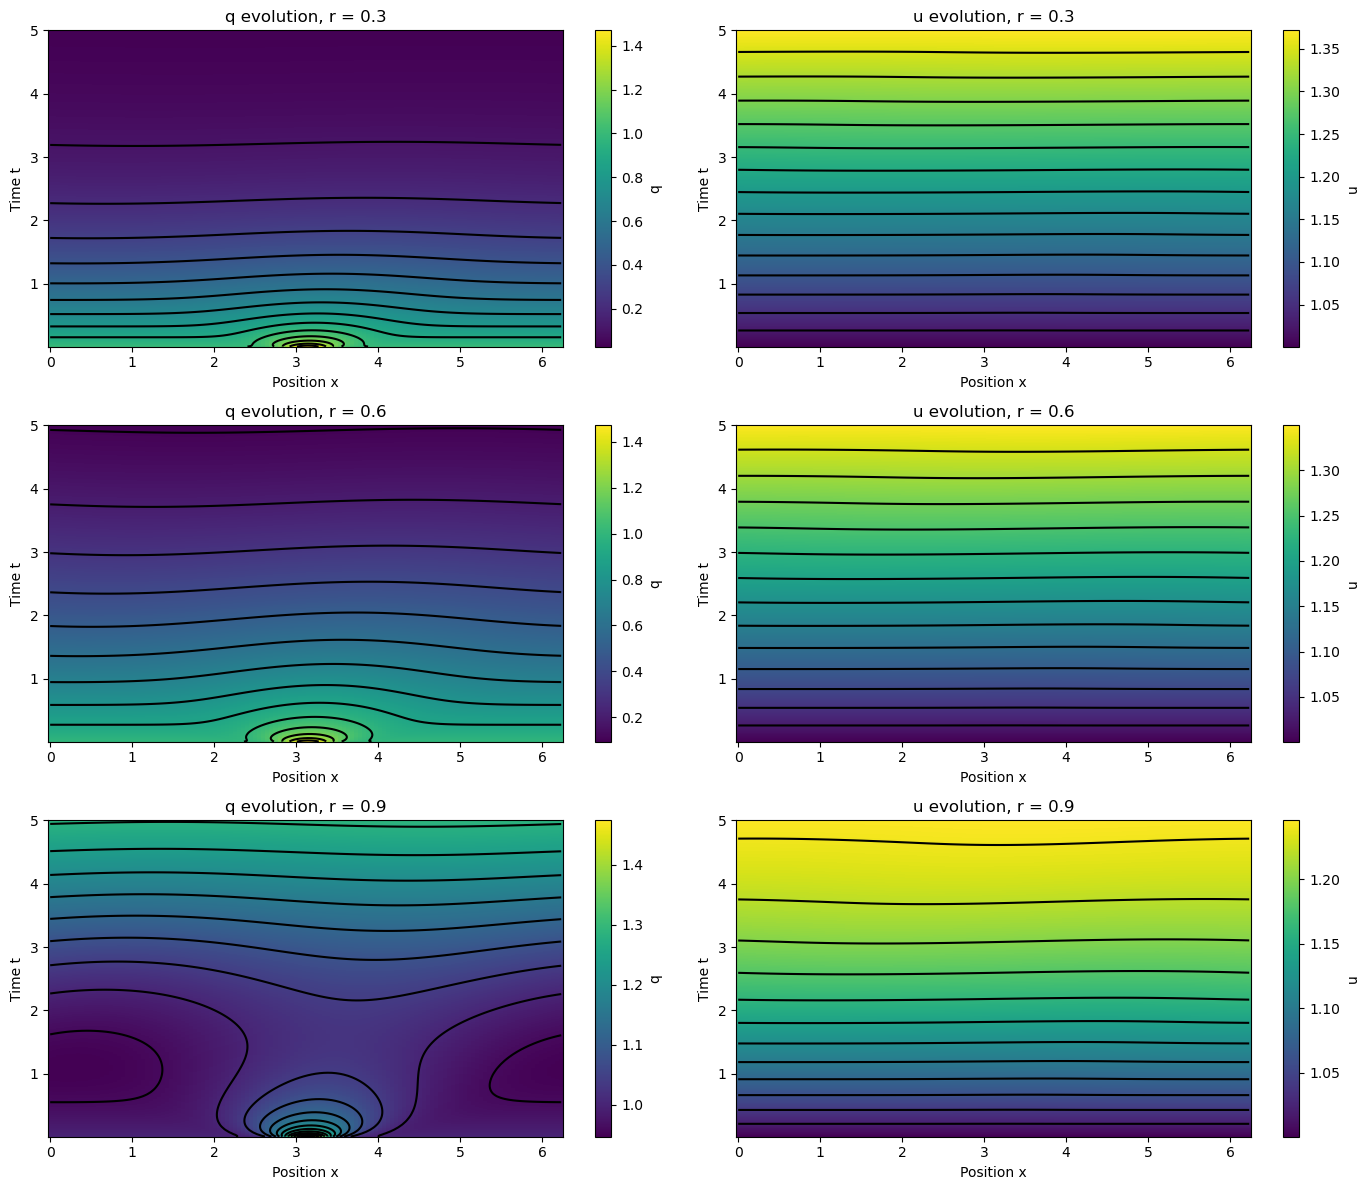

In [6]:
#Total plot of different r values, probably best to mainly use this
fig, ax = plt.subplots(len(r_values), 2, figsize=(14, 12))

for idx, r in enumerate(r_values):
    u_data, q_data, times = results[r]

    # Left column: q
    mesh1 = ax[idx, 0].pcolormesh(x, times, q_data)
    ax[idx, 0].contour(x, times, q_data, levels=15,colors='black')
    ax[idx, 0].set_title(f'q evolution, r = {r}')
    ax[idx, 0].set_xlabel('Position x')
    ax[idx, 0].set_ylabel('Time t')
    fig.colorbar(mesh1, ax=ax[idx, 0], label='q')

    # Right column: u
    mesh2 = ax[idx, 1].pcolormesh(x, times, u_data)
    ax[idx, 1].contour(x, times, u_data, levels=15,colors='black')
    ax[idx, 1].set_title(f'u evolution, r = {r}')
    ax[idx, 1].set_xlabel('Position x')
    ax[idx, 1].set_ylabel('Time t')
    fig.colorbar(mesh2, ax=ax[idx, 1], label='u')

plt.tight_layout()
plt.show()